<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/02_time_series/04_classification_app_human_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📱 Application · Human activity recognition: your phone knows what you are doing

Your phone counts your steps, notices when you start running, and some watches call for help after a fall. How?
Inside every smartphone there is an **accelerometer** (it measures acceleration along 3 axes) and a **gyroscope**
(it measures rotation). Together they produce a few *time series* that change shape depending on what you do.

**Genoa, Italy, 2012.** Researchers (Anguita, Ghio, Oneto, Parra and Reyes-Ortiz) strapped a Samsung Galaxy S II to
the waist of **30 volunteers** aged 19 to 48 and filmed them while they walked, climbed stairs, sat, stood and lay
down. The sensors were sampled 50 times per second and cut into windows of **2.56 seconds (128 readings)**. The
resulting *UCI HAR* dataset became a reference benchmark for wearable sensing.

**Our mission:** from one window of 9 sensor signals, recognise the activity among 6 classes. This is
**multivariate time-series classification**.

| Phase | Why it matters |
|---|---|
| 1. Load the raw signals | turn text files into a `(windows, channels, time)` array |
| 2. Explore | see how each activity "looks" for the sensors |
| 3. Choose the validation | **new users** at test time → split by person (and see what happens if we don't) |
| 4. MiniRocket | a strong, fast, training-free feature extractor |
| 5. A 1D convolutional neural network | our first deep learning model on time series |
| 6. Error analysis | which activities are confused, and why |

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "aeon"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

quest("Your phone knows what you are doing", chapter="Track 2 · Time series · Classification (application)", xp=250)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Your phone knows what you are doing
   Track 2 · Time series · Classification (application)
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load the raw inertial signals 📥

The archive (60 MB) contains another zip. Inside, `Inertial Signals/` holds one text file per channel:
`total_acc` (raw acceleration, including gravity), `body_acc` (gravity removed) and `body_gyro` (rotation), each on
axes x, y, z = **9 channels**. The authors already split the 30 volunteers into 21 for training and 9 for testing.

In [3]:
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
har_dir = DATA_DIR / "har"
root = har_dir / "UCI HAR Dataset"
if not (root / "train").exists():
    download_and_extract(URL, "har", marker="UCI HAR Dataset.zip")
    extract(har_dir / "UCI HAR Dataset.zip", har_dir)          # the zip inside the zip
    (har_dir / "UCI HAR Dataset.zip").unlink(missing_ok=True)

CHANNELS = [f"{sig}_{axis}" for sig in ("total_acc", "body_acc", "body_gyro") for axis in "xyz"]
ACTIVITIES = {1: "WALKING", 2: "UPSTAIRS", 3: "DOWNSTAIRS", 4: "SITTING", 5: "STANDING", 6: "LAYING"}

def load_split(split: str):
    signals = [pd.read_csv(root / split / "Inertial Signals" / f"{ch}_{split}.txt", sep=r"\s+", header=None).to_numpy()
               for ch in CHANNELS]
    X = np.stack(signals, axis=1).astype(np.float32)                       # (windows, 9, 128)
    y = pd.read_csv(root / split / f"y_{split}.txt", header=None)[0].to_numpy()
    subjects = pd.read_csv(root / split / f"subject_{split}.txt", header=None)[0].to_numpy()
    return X, y, subjects

X_train, y_train, subj_train = load_split("train")
X_test, y_test, subj_test = load_split("test")
print(f"train: {X_train.shape} from {len(np.unique(subj_train))} people · test: {X_test.shape} from {len(np.unique(subj_test))} people")

train: (7352, 9, 128) from 21 people · test: (2947, 9, 128) from 9 people


## 2. What does an activity look like? 🔍

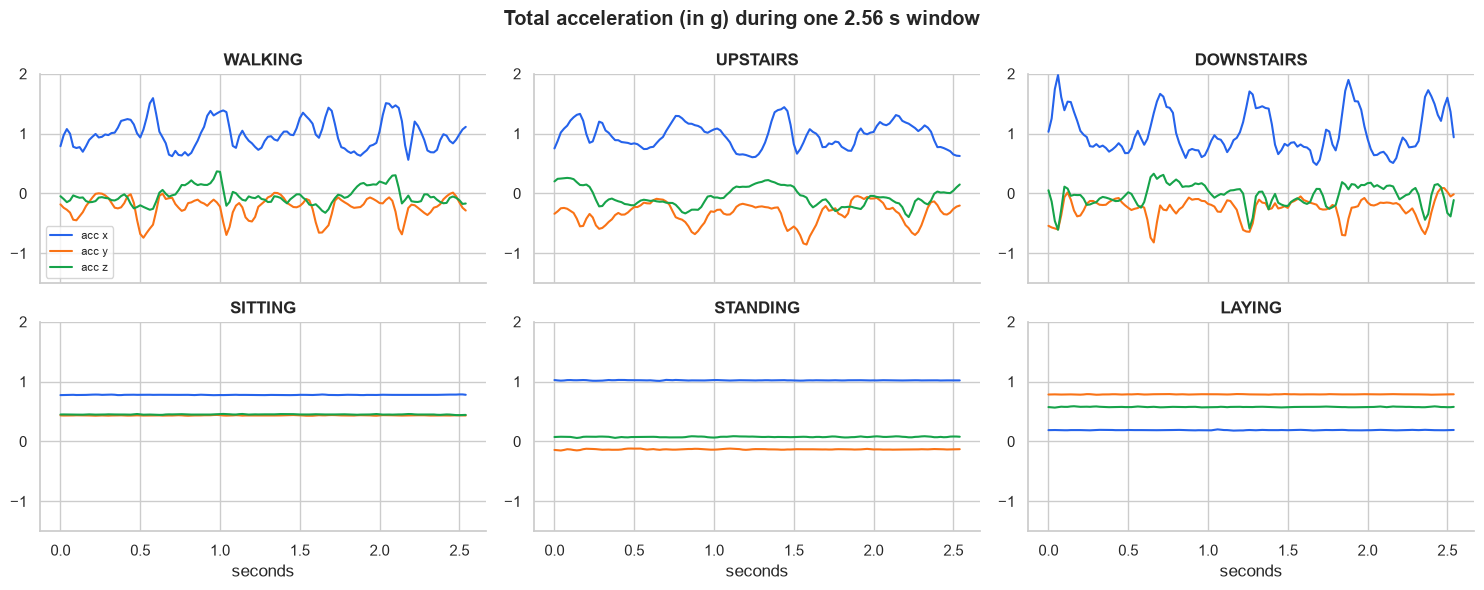

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
t = np.arange(128) / 50                                                  # seconds
for ax, (code, name) in zip(axes.ravel(), ACTIVITIES.items()):
    i = np.where(y_train == code)[0][10]
    for c, axis in enumerate("xyz"):
        ax.plot(t, X_train[i, c], label=f"acc {axis}")
    ax.set(title=name, ylim=(-1.5, 2.0))
axes[0, 0].legend(fontsize=8); [a.set_xlabel("seconds") for a in axes[1]]
plt.suptitle("Total acceleration (in g) during one 2.56 s window", fontweight="bold"); plt.tight_layout(); plt.show()

**Reading the charts:**
- The three **moving** activities oscillate with each step (≈ 2 steps per second). Upstairs and downstairs differ in
  rhythm and intensity.
- The three **static** activities are flat lines. What differs is the **orientation of gravity**: lying down, the
  phone is rotated, so gravity (1 g) moves from the x-axis to another axis. Sitting vs standing look almost the same
  for a waist-mounted phone: expect confusion there!

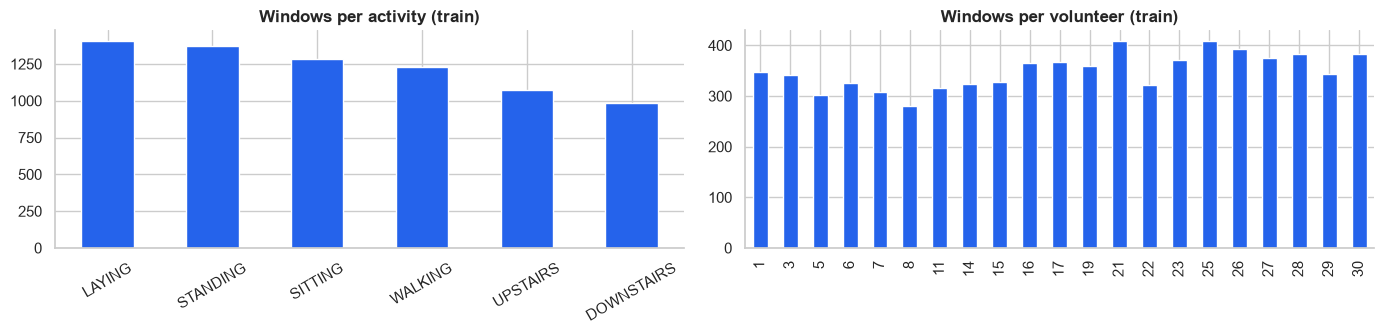

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
pd.Series(y_train).map(ACTIVITIES).value_counts().plot.bar(ax=axes[0], title="Windows per activity (train)", rot=30)
pd.Series(subj_train).value_counts().sort_index().plot.bar(ax=axes[1], title="Windows per volunteer (train)")
plt.tight_layout(); plt.show()

The classes are reasonably balanced, so **accuracy** is a fair metric.

## 3. The validation trap: split by person 🧩

The app will be used by **new people**, whose gait the model has never seen. Also, consecutive windows overlap by
50%, so two neighbouring windows share half their readings. If we split windows at random, the model sees almost the
same signal in training and validation and the score becomes over-optimistic (remember the patients of the
playbook?).

Let's measure it with a quick model: a Random Forest on simple statistics of each channel.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

def channel_stats(X):
    return np.concatenate([X.mean(2), X.std(2), X.min(2), X.max(2), np.abs(np.diff(X, axis=2)).mean(2)], axis=1)

S_train, S_test = channel_stats(X_train), channel_stats(X_test)
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
random_cv = cross_val_score(rf, S_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED)).mean()
person_cv = cross_val_score(rf, S_train, y_train, cv=GroupKFold(5), groups=subj_train).mean()
test_acc = accuracy_score(y_test, rf.fit(S_train, y_train).predict(S_test))

pd.DataFrame({"estimate": ["random KFold (windows mixed)", "GroupKFold (by person)", "reality: 9 new people"],
              "accuracy": [random_cv, person_cv, test_acc]}).round(3)

,estimate,accuracy
0,random KFold (windows mixed),0.981
1,GroupKFold (by person),0.890
2,reality: 9 new people,0.869


The random split promises more than reality delivers; the split **by person** is the honest one. From now on we use
the official person-wise split, and for the neural network we will hold out whole volunteers for validation.

In [7]:
lb = Leaderboard("har", metric="accuracy")
lb.add("Channel stats + RandomForest", test_acc)
checkpoint("har/validation", xp=50)

📋 Channel stats + RandomForest: accuracy = 0.86868
✅ Checkpoint · har/validation (+50 XP)
   ████████████░░░░░░░░░░░░ 50/100 XP


## 4. MiniRocket: random convolutions, multivariate edition 🚀

MiniRocket (seen in the GunPoint quest) also handles several channels: its random kernels look at combinations of
channels. We fit it on the 9-channel windows directly.

In [8]:
from aeon.classification.convolution_based import MiniRocketClassifier

t0 = time.perf_counter()
minirocket = MiniRocketClassifier(random_state=SEED, n_jobs=-1).fit(X_train, y_train)
pred_mr = minirocket.predict(X_test)
lb.add("MiniRocket", accuracy_score(y_test, pred_mr), seconds=round(time.perf_counter() - t0, 1))

📋 MiniRocket: accuracy = 0.97319  👑 new best!


## 5. A 1D convolutional neural network 🧠

Time for deep learning. A **1D-CNN** slides small learnable filters along time, exactly like an image CNN slides
filters over pixels. The first layers learn tiny patterns (a peak, a step impact), deeper layers combine them into
bigger ones (a stride, a stair climb), and a final layer votes for a class. Unlike MiniRocket, the filters are
**learned** from the data by gradient descent.

**The training vocabulary**
- **batch**: a small group of windows processed together (64 here),
- **loss**: how wrong the predictions are (cross-entropy for classification),
- **optimizer**: the rule that nudges the weights to reduce the loss (AdamW),
- **epoch**: one full pass over the training set,
- **validation set**: here **4 volunteers** held out from training, to pick the best epoch honestly.

In [9]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

device = get_device()
seed_everything(SEED)                     # torch is now loaded: seed it too

# Normalise each channel with statistics from the training windows only (no leakage!)
mean = X_train.mean(axis=(0, 2), keepdims=True); std = X_train.std(axis=(0, 2), keepdims=True)
norm = lambda X: (X - mean) / std

val_people = np.unique(subj_train)[-4:]
is_val = np.isin(subj_train, val_people)
def loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(norm(X)), torch.tensor(y - 1))          # classes 1..6 → 0..5
    return DataLoader(ds, batch_size=64, shuffle=shuffle, num_workers=NUM_WORKERS)
train_dl = loader(X_train[~is_val], y_train[~is_val], True)
val_dl = loader(X_train[is_val], y_train[is_val], False)
test_dl = loader(X_test, y_test, False)
print(f"training windows: {(~is_val).sum()} · validation windows: {is_val.sum()} (people {[int(p) for p in val_people]})")

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
training windows: 5867 · validation windows: 1485 (people [27, 28, 29, 30])


In [10]:
class HARNet(nn.Module):
    def __init__(self, n_channels=9, n_classes=6):
        super().__init__()
        def block(c_in, c_out, k):
            return nn.Sequential(nn.Conv1d(c_in, c_out, k, padding=k // 2), nn.BatchNorm1d(c_out), nn.ReLU())
        self.features = nn.Sequential(
            block(n_channels, 64, 7), block(64, 64, 5), nn.MaxPool1d(2),      # 128 → 64 time steps
            block(64, 128, 5), nn.MaxPool1d(2),                               # 64 → 32
            block(128, 128, 3), nn.AdaptiveAvgPool1d(1),                      # average over time
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

model = HARNet().to(device)
print(f"HARNet: {sum(p.numel() for p in model.parameters()):,} learnable weights")

HARNet: 116,550 learnable weights


In [11]:
def evaluate(model, dl):
    model.eval(); preds = []
    with torch.no_grad():
        for xb, _ in dl:
            preds.append(model(xb.to(device)).argmax(1).cpu())
    return torch.cat(preds).numpy()

EPOCHS = 20
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=2e-3, total_steps=EPOCHS * len(train_dl))
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05)
history, best_acc, best_state = [], 0.0, None
t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train(); running = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward(); optimizer.step(); scheduler.step()
        running += loss.item() * len(xb)
    val_acc = accuracy_score(y_train[is_val] - 1, evaluate(model, val_dl))
    history.append({"epoch": epoch, "train_loss": running / len(train_dl.dataset), "val_acc": val_acc})
    if val_acc > best_acc:
        best_acc, best_state = val_acc, {k: v.detach().clone() for k, v in model.state_dict().items()}
    if epoch % 4 == 0 or epoch == 1:
        print(f"epoch {epoch:2d} · train loss {history[-1]['train_loss']:.3f} · val accuracy {val_acc:.3f}")
cnn_seconds = time.perf_counter() - t0
model.load_state_dict(best_state)
print(f"best validation accuracy: {best_acc:.3f} · training time {cnn_seconds:.0f}s on {device}")

epoch  1 · train loss 1.033 · val accuracy 0.914


epoch  4 · train loss 0.358 · val accuracy 0.921


epoch  8 · train loss 0.349 · val accuracy 0.919


epoch 12 · train loss 0.329 · val accuracy 0.934


epoch 16 · train loss 0.320 · val accuracy 0.935


epoch 20 · train loss 0.313 · val accuracy 0.931
best validation accuracy: 0.941 · training time 73s on mps


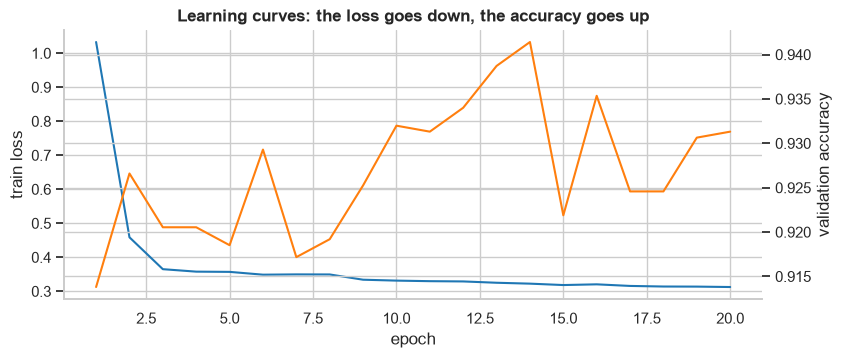

In [12]:
h = pd.DataFrame(history).set_index("epoch")
fig, ax1 = plt.subplots(figsize=(9, 3.5))
h["train_loss"].plot(ax=ax1, color="tab:blue", label="train loss"); ax1.set_ylabel("train loss")
h["val_acc"].plot(ax=ax1.twinx(), color="tab:orange", label="val accuracy").set_ylabel("validation accuracy")
ax1.set_title("Learning curves: the loss goes down, the accuracy goes up"); plt.show()

In [13]:
pred_cnn = evaluate(model, test_dl) + 1
lb.add("1D-CNN (HARNet)", accuracy_score(y_test, pred_cnn), seconds=round(cnn_seconds, 1))
lb.show()

📋 1D-CNN (HARNet): accuracy = 0.93044


,,model,accuracy,seconds
rank,,,,
1,🥇,MiniRocket,0.97319,176.2
2,🥈,1D-CNN (HARNet),0.93044,72.6
3,🥉,Channel stats + RandomForest,0.86868,NaN


In [14]:
checkpoint("har/models", xp=80)

✅ Checkpoint · har/models (+80 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ███░░░░░░░░░░░░░░░░░░░░░ 130/300 XP


## 6. Error analysis: who gets confused? 🔎

A single accuracy number hides *where* the model fails. The **confusion matrix** counts, for each true activity
(rows), which activity was predicted (columns).

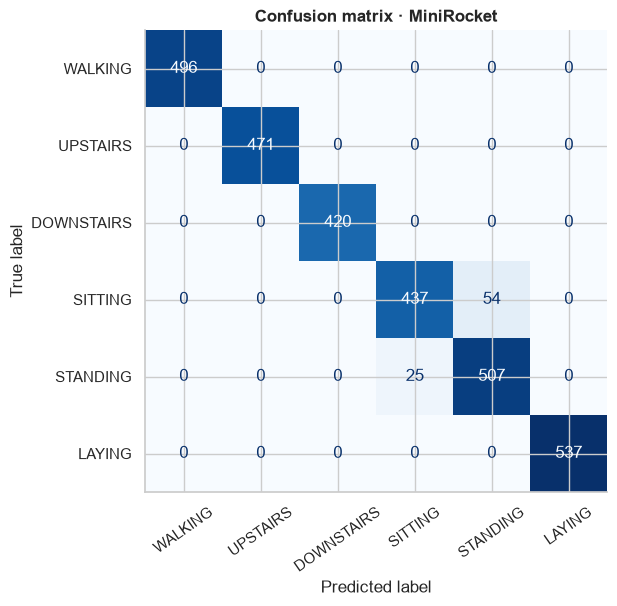

79 errors out of 2947 windows. Most frequent confusions (true → predicted):
SITTING → STANDING    54
STANDING → SITTING    25


In [15]:
best_name = lb.best()["model"]
best_pred = {"MiniRocket": pred_mr, "1D-CNN (HARNet)": pred_cnn}.get(best_name, pred_cnn)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred), display_labels=list(ACTIVITIES.values())).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35)
ax.set_title(f"Confusion matrix · {best_name}"); plt.show()

names = np.array(list(ACTIVITIES.values()))
errors = pd.Series([f"{names[t - 1]} → {names[p - 1]}" for t, p in zip(y_test, best_pred) if t != p])
print(f"{len(errors)} errors out of {len(y_test)} windows. Most frequent confusions (true → predicted):")
print(errors.value_counts().head(4).to_string())

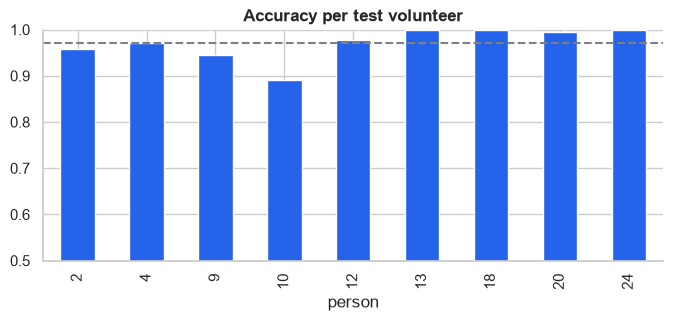

In [16]:
per_person = pd.DataFrame({"person": subj_test, "correct": best_pred == y_test}).groupby("person")["correct"].mean()
per_person.plot.bar(title="Accuracy per test volunteer", ylim=(0.5, 1), figsize=(8, 3)); plt.axhline(per_person.mean(), ls="--", c="gray"); plt.show()

**What we see:**
- Moving activities and *lying* are recognised almost perfectly.
- Most errors are **sitting ↔ standing**: for a phone on the waist, both are "still and upright". A phone in the
  pocket (on the thigh) would see the leg angle and separate them easily: **sensor placement is a feature too**.
- Accuracy varies from one person to another: everyone moves differently, which is exactly why we validate on
  unseen people.

## 🏁 What did we learn?
- Multivariate sensor data is a `(windows, channels, time)` array; normalise channels with **training** statistics.
- **Split by person** when the model will meet new people: random window splits overestimate the score.
- **MiniRocket** gives the top result with no tuning; a small **1D-CNN** learns its own filters and gets close, in a
  fraction of the time on a GPU (and it is the starting point for bigger deep models).
- The confusion matrix tells you what to fix next (here: sitting vs standing).

### 🚀 Your turn (bonus XP)
1. Train the CNN only on `total_acc_*` channels (3 instead of 9). How much does the gyroscope help?
2. Add a **GRU** or **LSTM** layer after the convolutions (`nn.GRU(128, 64, batch_first=True)`): does modelling the order
   of the features help?
3. Average the predictions of MiniRocket and the CNN (majority vote with the Random Forest as tie-breaker).
4. Data augmentation: add small random noise or scale the signals during training. Better generalisation to new
   people?
5. A real challenge with wearable sensors: Kaggle's *CMI · Detect Behavior with Sensor Data* (2025) asked to recognise
   gestures from a wrist device, with exactly the tools of this notebook.

In [17]:
checkpoint("har/complete", xp=120)
badge("Motion Decoder", "📱")
progress()

✅ Checkpoint · har/complete (+120 XP)
   ██████████████████░░░░░░ 250/300 XP
╔═══════════════════════════════════╗
║ 📱  BADGE UNLOCKED: Motion Decoder ║
╚═══════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 3
Badges: 📱 Motion Decoder
